In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/college_student_placement_dataset.csv')

In [3]:
df.head()

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No


In [4]:
df.tail()

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
9995,CLG0021,119,8.41,8.29,4,No,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,7,No,0,7,2,No
9997,CLG0066,89,6.08,6.25,3,Yes,3,9,5,No
9998,CLG0045,107,8.77,8.92,3,No,7,5,1,No
9999,CLG0060,109,9.41,9.77,8,No,3,5,5,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   College_ID              10000 non-null  object 
 1   IQ                      10000 non-null  int64  
 2   Prev_Sem_Result         10000 non-null  float64
 3   CGPA                    10000 non-null  float64
 4   Academic_Performance    10000 non-null  int64  
 5   Internship_Experience   10000 non-null  object 
 6   Extra_Curricular_Score  10000 non-null  int64  
 7   Communication_Skills    10000 non-null  int64  
 8   Projects_Completed      10000 non-null  int64  
 9   Placement               10000 non-null  object 
dtypes: float64(2), int64(5), object(3)
memory usage: 781.4+ KB


In [6]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

,0
College_ID,0
IQ,0
Prev_Sem_Result,0
CGPA,0
Academic_Performance,0
Internship_Experience,0
Extra_Curricular_Score,0
Communication_Skills,0
Projects_Completed,0
Placement,0


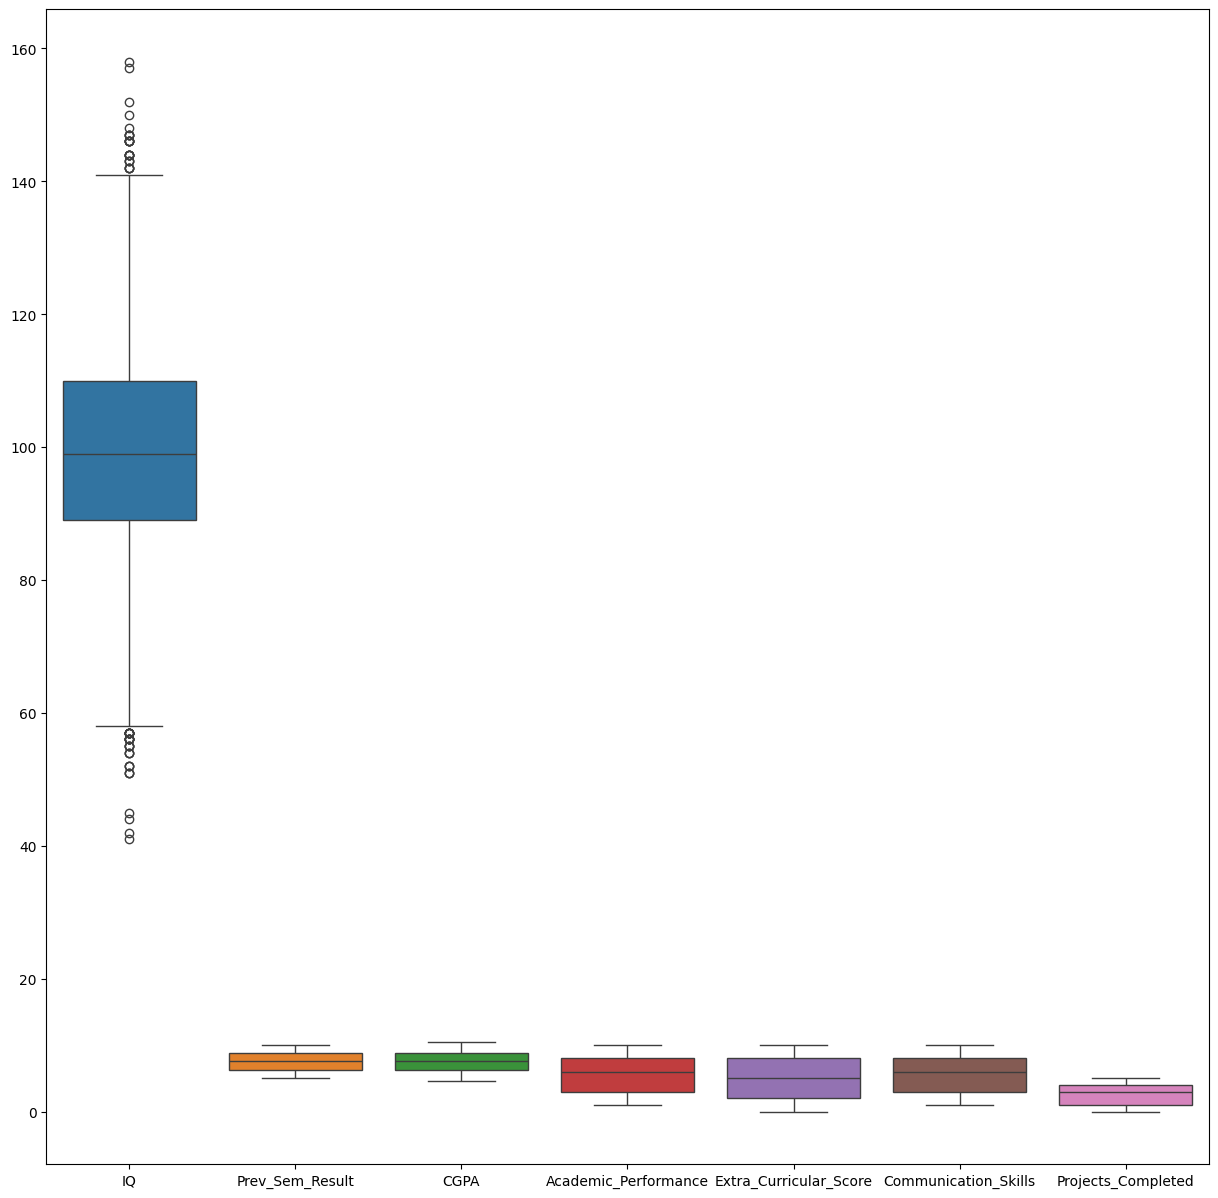

In [7]:
plt.figure(figsize=(15,15))
sns.boxplot(data = df.select_dtypes(include='number'))
plt.show()

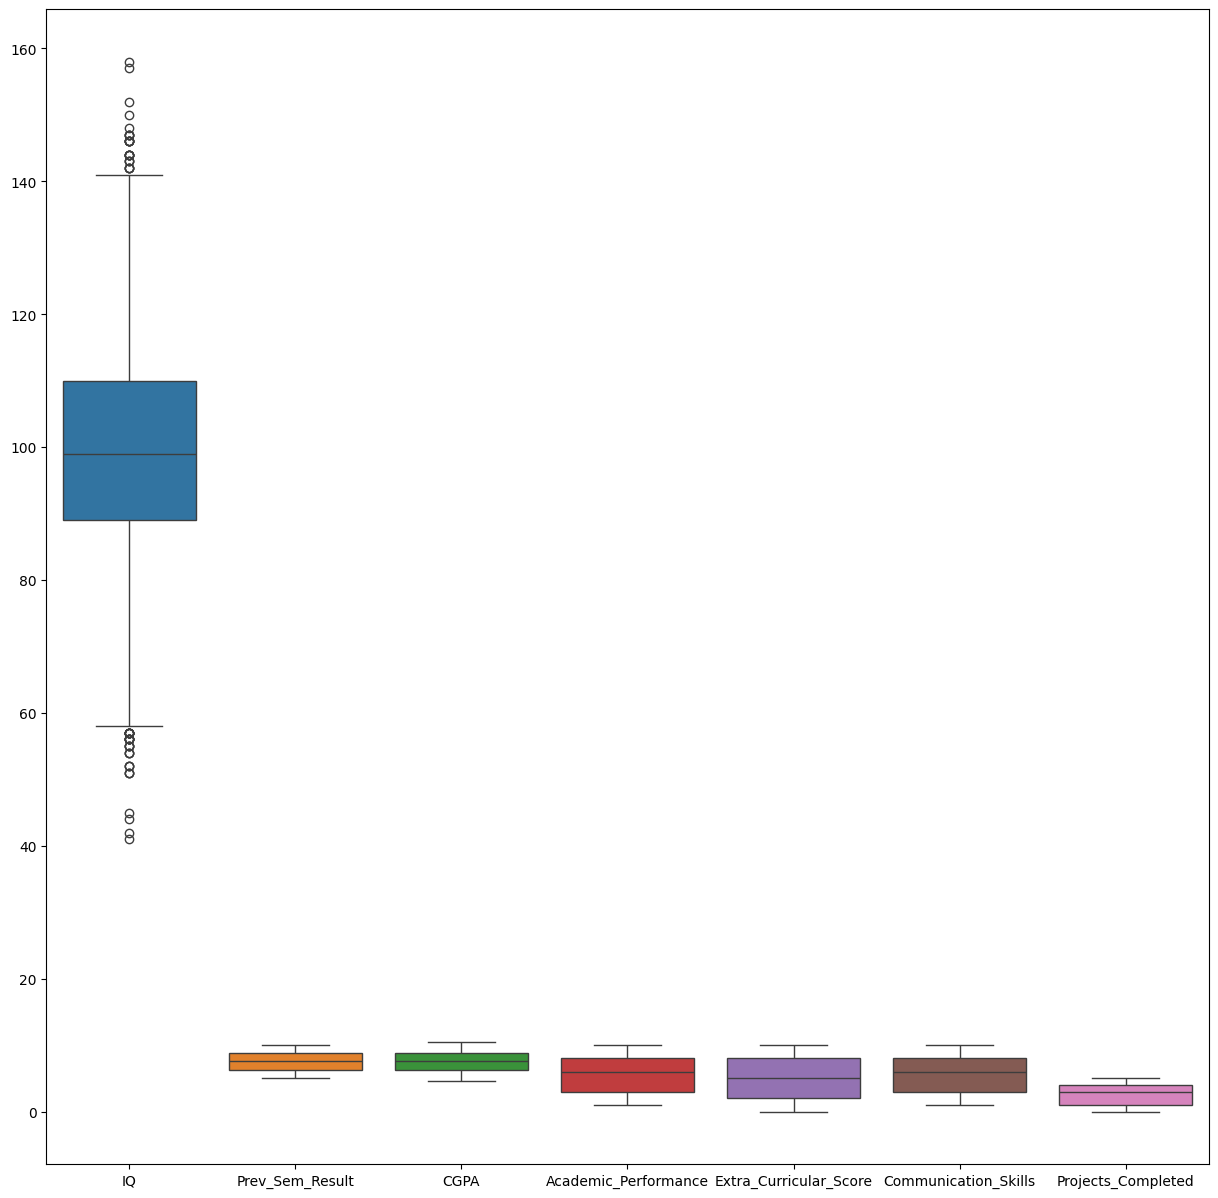

In [8]:
# for loop
for col in df.select_dtypes(include ='number').columns:
  if col == "college_ID":
    continue
plt.figure(figsize=(15,15))
sns.boxplot(data = df.select_dtypes(include='number'))
plt.show()

In [11]:
# Outlier treatment
df.columns = df.columns.str.strip()

columns = [
    'Communication_Skills',
    'Extra_Curricular_Score',
]

for i in columns:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3-Q1
  lower_bound = Q1 - 1.5*IQR
  upper_bound = Q3 + 1.5*IQR

  df[i] = np.where(df[i] < lower_bound, lower_bound, df[i])
  df[i] = np.where(df[i] > upper_bound, upper_bound, df[i])

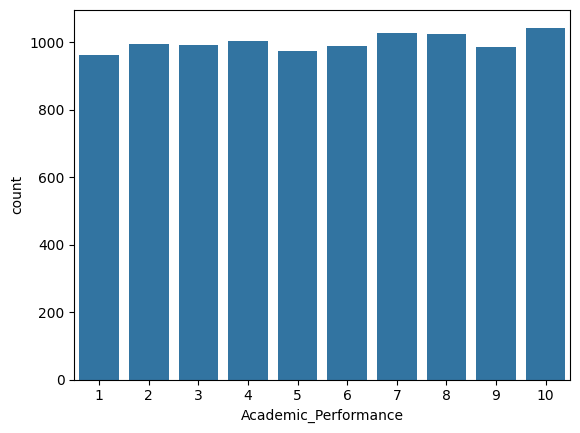

In [17]:
sns.countplot(data=df, x='Academic_Performance')
plt.show()

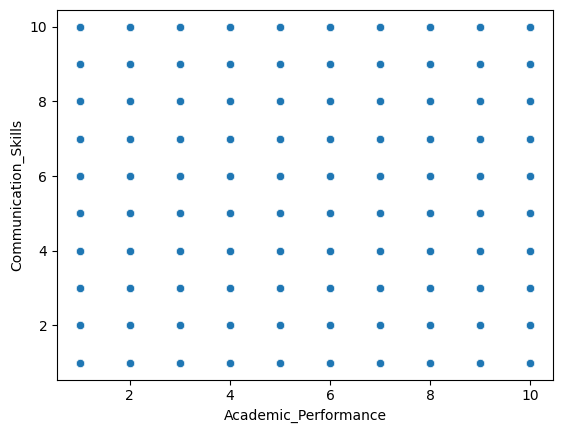

In [19]:
sns.scatterplot(x = df['Academic_Performance'],y= df['Extra_Curricular_Course'])
plt.show()

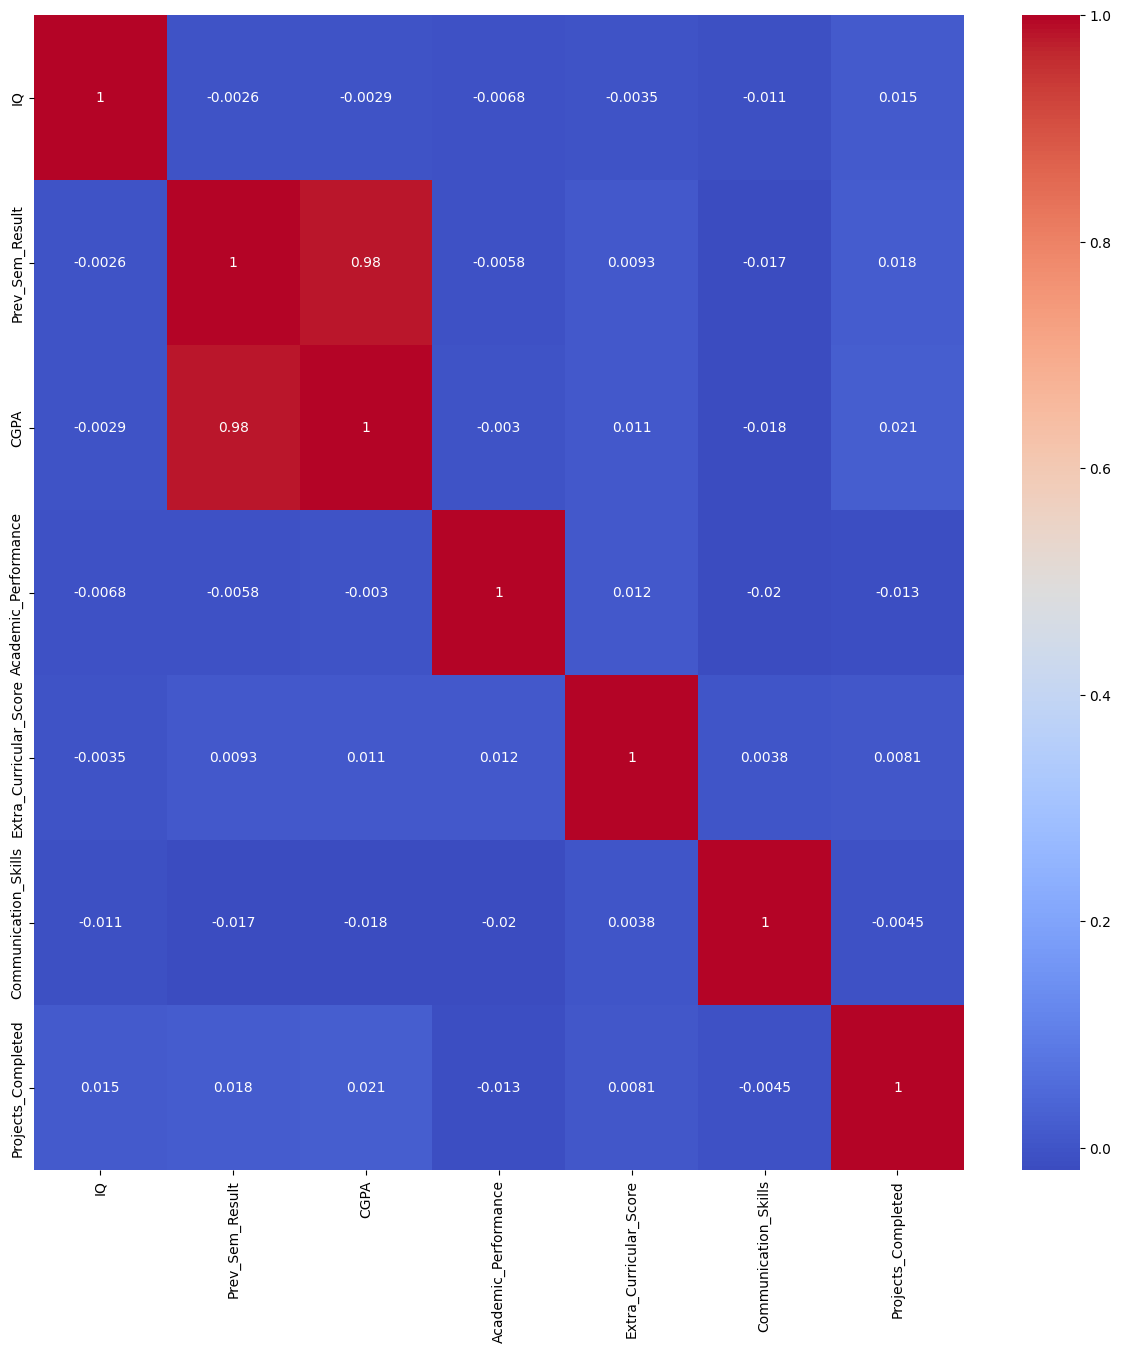

In [20]:
plt.figure(figsize=(15,15))
sns.heatmap(df.select_dtypes(include='number').drop(columns = 'College_ID',errors ='ignore').corr(), annot=True,cmap =  'coolwarm')
plt.show()

In [21]:
df.select_dtypes(include ='object').columns

Index(['College_ID', 'Internship_Experience', 'Placement'], dtype='object')

In [22]:
df.columns = df.columns.str.strip()
for  col in df.select_dtypes(include ='object').columns:
     df[col] = df[col].str.strip()

In [25]:
df['College_ID'] = df['College_ID'].map({'Graduate': 1, 'Not Graduate': 0})
df['Internship_Experience'] = df['Internship_Experience'].map({'Yes': 1, 'No': 0})
df['Placement'] = df['Placement'].map({'Y': 1, 'N': 0})

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   College_ID              0 non-null      float64
 1   IQ                      10000 non-null  int64  
 2   Prev_Sem_Result         10000 non-null  float64
 3   CGPA                    10000 non-null  float64
 4   Academic_Performance    10000 non-null  int64  
 5   Internship_Experience   0 non-null      float64
 6   Extra_Curricular_Score  10000 non-null  float64
 7   Communication_Skills    10000 non-null  float64
 8   Projects_Completed      10000 non-null  int64  
 9   Placement               0 non-null      float64
dtypes: float64(7), int64(3)
memory usage: 781.4 KB


In [27]:
# Divide the dataset into X, & Y
X = df.drop(columns=['College_ID','Placement'])
Y = df['Placement']

In [28]:
# Train test
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [29]:
# Model
from sklearn.model_selection import train_test_split
X_train

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed
9254,103,7.30,6.96,10,NaN,6.0,6.0,1
1561,88,5.49,5.02,3,NaN,2.0,4.0,1
1670,96,6.86,6.99,4,NaN,9.0,5.0,4
6087,76,6.09,6.22,2,NaN,6.0,7.0,1
6669,110,8.19,8.06,2,NaN,1.0,1.0,2
...,...,...,...,...,...,...,...,...
5734,91,9.93,9.72,6,NaN,8.0,8.0,1
5191,99,7.74,7.36,9,NaN,7.0,10.0,0
5390,89,7.07,6.66,1,NaN,10.0,1.0,5
860,103,7.74,7.57,4,NaN,8.0,3.0,2
